# **Aula 07 — Da rede neural à PINN com DeepXDE**

## Equação de calor unidimensional

Este notebook acompanha o roteiro de lousa roteiro_lousa_pinn.tex. A proposta é identificar, no código, os mesmos elementos apresentados matematicamente:

- domínio do problema;
- equação diferencial;
- condições de contorno e inicial;
- rede neural aproximadora;
- pontos de treinamento;
- função de perda;
- otimização;
- validação da solução.

O exemplo é um problema direto de condução de calor. A solução analítica será utilizada apenas para validar a PINN depois do treinamento.

> **Paralelo com a lousa** aqui pode ser entendido como as explicações no documento fornecido para aula e disponível no repositório.

## 1. Formulação matemática

Consideramos a equação de calor unidimensional

$$
\frac{\partial u}{\partial t}
= \alpha \frac{\partial^2 u}{\partial x^2},
\qquad 0 < x < L,\quad 0 < t < 1.
$$

Com condições de contorno de Dirichlet

$$
u(0,t)=0, \qquad u(L,t)=0,
$$

e condição inicial

$$
u(x,0)=\sin\left(\frac{\pi x}{L}\right).
$$

A solução analítica conhecida é

$$
u_{\mathrm{exata}}(x,t)
= \exp\left(-\frac{\alpha\pi^2}{L^2}t\right)
\sin\left(\frac{\pi x}{L}\right).
$$

### Paralelo com a lousa

Na lousa, essa equação foi escrita como um problema físico. No DeepXDE, cada parte da formulação será transformada em um objeto ou função do programa.


**instalando o DeepXDE**

In [126]:
# Se necessário no Google Colab, execute esta célula uma única vez:
!pip -q install deepxde

import deepxde as dde
import numpy as np
import matplotlib.pyplot as plt

print("DeepXDE:", dde.__version__)


DeepXDE: 1.15.1


## 2. Parâmetros do problema

Nesta implementação, usamos o mesmo domínio adimensional do exemplo clássico do DeepXDE. O valor de alpha controla a velocidade de difusão da solução.

### Paralelo com a lousa

Esses valores correspondem às constantes que aparecem na equação diferencial escrita na primeira parte do roteiro.


In [127]:
# Parâmetros físicos/matemáticos
alpha = 0.4
L = 1.0
t_inicio = 0.0
t_final = 1.0


## 3. Domínio computacional

A PINN precisa saber em qual região do espaço e do tempo deve satisfazer a equação. Para isso, combinamos um intervalo espacial com um domínio temporal.

### Paralelo com a lousa

A instrução GeometryXTime representa o domínio

$$
(x,t) \in [0,L]\times[0,1].
$$


In [128]:
geom = dde.geometry.Interval(0, L)
timedomain = dde.geometry.TimeDomain(t_inicio, t_final)
geomtime = dde.geometry.GeometryXTime(geom, timedomain)


## 4. Resíduo da equação diferencial

A rede neural produzirá uma aproximação

$$
u(x,t) \approx u_{\theta}(x,t).
$$

Substituindo essa aproximação na equação de calor, obtemos o resíduo

$$
r_{\theta}(x,t)
= \frac{\partial u_{\theta}}{\partial t}
- \alpha\frac{\partial^2u_{\theta}}{\partial x^2}.
$$

A PINN será treinada para que esse resíduo seja próximo de zero nos pontos internos do domínio.

### Paralelo com a lousa

* u representa a saída da rede,
* du_t representa a derivada temporal e
* du_xx representa a segunda derivada espacial.

As derivadas são obtidas por diferenciação automática.


In [129]:
def pde(x, y):
    '''Resíduo da equação de calor.'''
    du_t = dde.grad.jacobian(y, x, i=0, j=1)
    du_xx = dde.grad.hessian(y, x, component = 0, i=0, j=0)
    return du_t - alpha * du_xx


No DeepXDE as operações de derivada de primeira ordem e de segunda ordem, já tem funções prontas para serem executadas:
* A derivada de 1 ordem esta associada ao `jacobiano`
* A derivada de 2 ordem esta associado ao `hessiano`

Como nosso modelo tem **2 entradas e 1 saída** precisamos indicar os índices i e j, basicamente o que definimos é:

* $x_0 = x$, $x_1 = t$
* $y_0 = u$
* no Jacobiano, i seleciona a saída e j a entrada;
* no Hessiano, i e j selecionam as duas direções de diferenciação; `component=0` seleciona $u$

---

Se houvessem duas saídas pra rede, por exemplo $u$ e $v$ e quisessemos as derivadas de primeira e segunda ordem de ambas com relação ao espaço e o tempo fariámos algo como:

```python
# ∂u/∂x
u_x = dde.grad.jacobian(y, x, i=0, j=0)

# ∂u/∂t
u_t = dde.grad.jacobian(y, x, i=0, j=1)

# ∂v/∂x
v_x = dde.grad.jacobian(y, x, i=1, j=0)

# ∂v/∂t
v_t = dde.grad.jacobian(y, x, i=1, j=1)

# ∂²u/∂x²
u_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)

# ∂²u/∂t²
u_tt = dde.grad.hessian(y, x, component=0, i=1, j=1)

# ∂²v/∂x²
v_xx = dde.grad.hessian(y, x, component=1, i=0, j=0)

# ∂²v/∂t²
v_tt = dde.grad.hessian(y, x, component=1, i=1, j=1)

# Derivada mista ∂²v/(∂x∂t)
v_xt = dde.grad.hessian(y, x, component=1, i=0, j=1)
```



## 5. Condições de contorno e condição inicial

As condições de contorno informam o valor de u nas duas extremidades da barra. A condição inicial informa o perfil no instante t=0.

### Paralelo com a lousa

Essas condições geram parcelas específicas da função de perda da PINN. A rede deve satisfazer simultaneamente a equação no interior e as condições nas fronteiras do domínio.


In [130]:
# bc: boundary condition
bc = dde.icbc.DirichletBC(
    geomtime,
    lambda x: 0.0,
    lambda _, on_boundary: on_boundary,
)

# ic: initial condition
ic = dde.icbc.IC(
    geomtime,
    lambda x: np.sin(np.pi * x[:, 0:1] / L),
    lambda _, on_initial: on_initial,
)


**explicação do trecho anterior**

```python
bc = dde.icbc.DirichletBC(
    geomtime,
    lambda x: 0.0,
    lambda _, on_boundary: on_boundary,
)
```
Aqui é definida a condição de contorno:
$$
u(0,t)=0,\qquad u(L,t)=0.
$$
- geomtime: domínio espacial e temporal do problema.
- lambda x: 0.0: estabelece que a temperatura deve ser zero na fronteira.
- lambda _, on_boundary: on_boundary: seleciona somente os pontos localizados na fronteira espacial. O símbolo _ indica que a coordenada do ponto não será utilizada nessa decisão.

Como a condição vale para as duas extremidades, o mesmo DirichletBC atende tanto a $x=0$ quanto a $x=L$.

```python
ic = dde.icbc.IC(
    geomtime,
    lambda x: np.sin(np.pi * x[:, 0:1] / L),
    lambda _, on_initial: on_initial,
)
```

Aqui é definida a condição inicial:
$$
u(x,0)=\sin\left(\frac{\pi x}{L}\right).
$$

- `lambda x: ...`: calcula o perfil inicial desejado.
- `x[:, 0:1]`: seleciona a primeira coluna das entradas, que corresponde à posição \(x\). A segunda coluna seria o tempo \(t\).
- `lambda _, on_initial`: on_initial: seleciona somente os pontos pertencentes ao instante inicial \(t=0\).

Em resumo, durante o treinamento a rede é penalizada quando:
1. produz valores diferentes de zero nas extremidades;
2. não reproduz o perfil inicial;
3. não satisfaz a equação diferencial no interior do domínio.
Essas condições não são impostas diretamente na saída da rede; elas entram como parcelas na função de perda.

## 6. Pontos de treinamento e função de perda

O objeto TimePDE amostra pontos internos, pontos de contorno e pontos no instante inicial. Esses pontos não precisam ser os nós de uma malha de diferenças finitas.

A função de perda pode ser entendida como

$$
\mathcal{L}
= \lambda_f\mathcal{L}_{\mathrm{PDE}}
+ \lambda_b\mathcal{L}_{\mathrm{BC}}
+ \lambda_i\mathcal{L}_{\mathrm{IC}}.
$$

na equação anterior os termos $\lambda$ são os chamados _loss weights_, no nosso exemplo adotaremos todos sendo iguais a 1.

Abaixo vamos definir as **informações** relacionadas a geometria, ao problema e a quantidade de pontos que queremos utilizar

In [131]:
data = dde.data.TimePDE(
    geomtime,
    pde,
    [bc, ic],
    num_domain=500,
    num_boundary=40,
    num_initial=80,
    num_test=400,
)


## 7. Rede neural aproximadora

A rede recebe duas entradas, x e t, e produz uma saída, $u_\theta(x,t)$.

A arquitetura escolhida é

$$
[2] \rightarrow [20] \rightarrow [20] \rightarrow [20] \rightarrow [1].
$$

### Paralelo com a lousa

A lista [2] + [20] * 3 + [1] representa exatamente o esquema desenhado: duas entradas, três camadas ocultas com vinte neurônios e uma saída.


In [132]:
net = dde.nn.FNN(
    [2] + [20] * 3 + [1],
    "tanh",
    "Glorot normal",
)


## 8. Compilação e treinamento

`compile` define o otimizador, a taxa de aprendizagem e as métricas. train realiza as atualizações dos pesos e vieses para reduzir a função de perda.

Neste exemplo, começamos com Adam. Depois, utilizamos L-BFGS como uma etapa de refinamento, estratégia comum em exemplos de PINNs.

### Paralelo com a lousa

O treinamento computacional é a implementação do problema

$$
\theta^* = \arg\min_{\theta}\mathcal{L}(\theta).
$$


In [133]:
model = dde.Model(data, net)

model.compile(
    "adam",
    lr=1e-3,
)

losshistory, train_state = model.train(
    iterations=1000,
    display_every=100,
)


Compiling model...
'compile' took 0.006720 s

Training model...



<unknown>:322: SyntaxWarning: invalid escape sequence '\m'
Cause: could not parse the source code of <function <lambda> at 0x7f2d5003d9e0>: no matching AST found among candidates:
# coding=utf-8
lambda x, on: np.array([on_boundary(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary1(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary2(x[i], on[i]) for i in range(len(x))])
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function <lambda> at 0x7f2d5003d9e0>: no matching AST found among candidates:
# coding=utf-8
lambda x, on: np.array([on_boundary(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary1(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary2(x[i], on[i]) for i in range(len(x))])
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


<unknown>:322: SyntaxWarning: invalid escape sequence '\m'
Cause: could not parse the source code of <function <lambda> at 0x7f2d507809a0>: no matching AST found among candidates:
# coding=utf-8
lambda x, on: np.array([on_boundary(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary1(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary2(x[i], on[i]) for i in range(len(x))])
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function <lambda> at 0x7f2d507809a0>: no matching AST found among candidates:
# coding=utf-8
lambda x, on: np.array([on_boundary(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary1(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary2(x[i], on[i]) for i in range(len(x))])
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Step      Train loss                        Test loss                         Test metric
0         [6.81e-02, 4.59e-02, 2.72e-01]    [6.59e-02, 4.59e-02, 2.72e-01]    []  
100       [2.48e-02, 4.61e-02, 8.68e-02]    [1.79e-02, 4.61e-02, 8.68e-02]    []  
200       [1.70e-02, 3.52e-02, 6.22e-02]    [1.05e-02, 3.52e-02, 6.22e-02]    []  
300       [8.22e-03, 1.73e-02, 3.12e-02]    [3.56e-03, 1.73e-02, 3.12e-02]    []  
400       [5.00e-03, 6.92e-03, 1.26e-02]    [2.77e-03, 6.92e-03, 1.26e-02]    []  
500       [

Após a etapa inicial com Adam, utilizamos o L-BFGS como refinamento.

O Adam conduz a rede até uma região adequada do espaço de parâmetros, enquanto o L-BFGS utiliza informações aproximadas de curvatura para buscar uma solução mais precisa.

In [135]:
# Refinamento com L-BFGS após o Adam
dde.optimizers.config.set_LBFGS_options(
    maxcor=20,     # quantidade de informações anteriores armazenadas
    ftol=1e-8,     # tolerância para a variação da loss
    gtol=1e-6,     # tolerância para o gradiente
    maxiter=300,   # limite total de iterações
    maxls=20,      # tentativas máximas na busca do passo
)

model.compile("L-BFGS")

losshistory, train_state = model.train()

Compiling model...
'compile' took 0.013547 s

Training model...

Step      Train loss                        Test loss                         Test metric
1000      [9.25e-04, 4.38e-04, 3.10e-04]    [4.60e-04, 4.38e-04, 3.10e-04]    []  
1300      [5.66e-05, 8.24e-06, 3.90e-06]    [3.67e-05, 8.24e-06, 3.90e-06]    []  

Best model at step 1300:
  train loss: 6.87e-05
  test loss: 4.89e-05
  test metric: []

'train' took 41.716279 s



**verificando o numero de parametros que foram treinados**

In [136]:
num_parametros = sum(
    int(np.prod(variavel.shape))
    for variavel in net.trainable_variables
)

print(f"Número de parâmetros treináveis: {num_parametros:,}")

Número de parâmetros treináveis: 921


## 9. Histórico da perda

O histórico permite acompanhar a evolução das parcelas da função de perda ao longo do treinamento. Uma redução da perda indica que a rede está encontrando uma função que satisfaz melhor as restrições impostas.


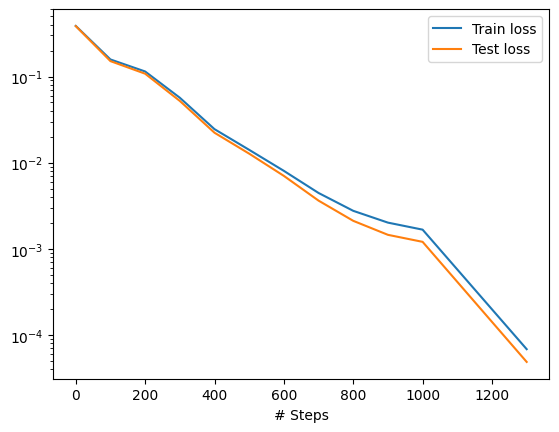

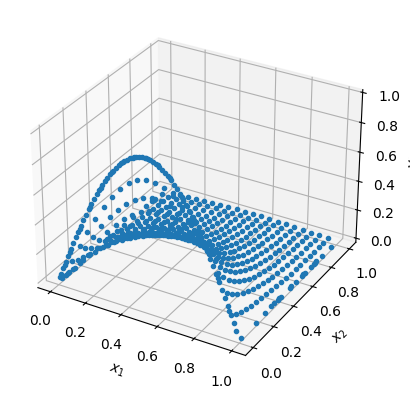

In [137]:
dde.saveplot(
    losshistory,
    train_state,
    issave=False,
    isplot=True,
)


## 10. Avaliação da solução

Depois do treinamento, avaliamos a rede em uma malha regular. A solução analítica é usada apenas para comparação, não como termo da função de perda do problema direto.


In [138]:
x_eval = np.linspace(0.0, L, 121)
t_eval = np.linspace(t_inicio, t_final, 101)

XX, TT = np.meshgrid(x_eval, t_eval, indexing="ij")
X_eval = np.column_stack((XX.ravel(), TT.ravel()))

u_pred = model.predict(X_eval).reshape(XX.shape)

u_exact = (
    np.exp(-alpha * np.pi**2 * TT / L**2)
    * np.sin(np.pi * XX / L)
)

error_abs = np.abs(u_exact - u_pred)

residual = model.predict(X_eval, operator=pde).reshape(XX.shape)

print("Erro absoluto máximo:", np.max(error_abs))
print("Resíduo médio absoluto:", np.mean(np.abs(residual)))
print(
    "Erro relativo L2:",
    dde.metrics.l2_relative_error(
        u_exact.reshape(-1, 1),
        u_pred.reshape(-1, 1),
    ),
)


Erro absoluto máximo: 0.008849844336509809
Resíduo médio absoluto: 0.0046536466
Erro relativo L2: 0.007569495712065717


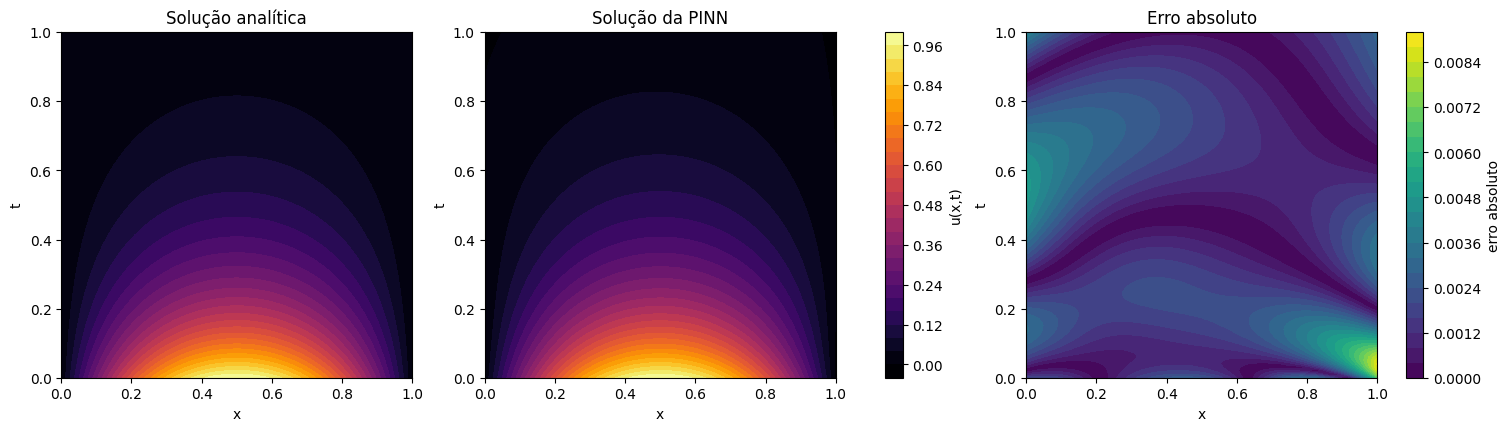

In [139]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.2),
    constrained_layout=True,
)

vmin = min(u_exact.min(), u_pred.min())
vmax = max(u_exact.max(), u_pred.max())

mapa_0 = axes[0].contourf(
    XX, TT, u_exact,
    levels=25,
    cmap="inferno",
    vmin=vmin,
    vmax=vmax,
)
axes[0].set_title("Solução analítica")

mapa_1 = axes[1].contourf(
    XX, TT, u_pred,
    levels=25,
    cmap="inferno",
    vmin=vmin,
    vmax=vmax,
)
axes[1].set_title("Solução da PINN")

mapa_2 = axes[2].contourf(
    XX, TT, error_abs,
    levels=25,
    cmap="viridis",
)
axes[2].set_title("Erro absoluto")

for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("t")

fig.colorbar(mapa_1, ax=axes[:2], label="u(x,t)")
fig.colorbar(mapa_2, ax=axes[2], label="erro absoluto")
plt.show()


## 11. Leitura final do exemplo

A implementação pode ser lida como uma tradução direta da formulação matemática:

| Formulação | DeepXDE |
|---|---|
| Domínio espacial e temporal | Interval, TimeDomain, GeometryXTime |
| Equação diferencial | função pde |
| Condição de contorno | DirichletBC |
| Condição inicial | IC |
| Pontos de treinamento | TimePDE |
| Solução aproximada | dde.nn.FNN |
| Otimização | compile e train |
| Validação | predict e solução analítica |

A principal mensagem é:

> A PINN utiliza uma rede neural como aproximadora, mas a função de perda é construída para que a aproximação respeite a equação física e as condições do problema.


## Codigo Completo

**instalacoes**

In [ ]:
# Se necessário no Google Colab, execute esta célula uma única vez:
!pip -q install deepxde

import deepxde as dde
import numpy as np
import matplotlib.pyplot as plt

print("DeepXDE:", dde.__version__)


**inicializacao e processamento**

In [ ]:
# Parâmetros físicos/matemáticos
alpha = 0.4
L = 1.0
t_inicio = 0.0
t_final = 1.0

geom = dde.geometry.Interval(0, L)
timedomain = dde.geometry.TimeDomain(t_inicio, t_final)
geomtime = dde.geometry.GeometryXTime(geom, timedomain)

def pde(x, y):
    '''Resíduo da equação de calor.'''
    du_t = dde.grad.jacobian(y, x, i=0, j=1)
    du_xx = dde.grad.hessian(y, x, component = 0, i=0, j=0)
    return du_t - alpha * du_xx


# bc: boundary condition
bc = dde.icbc.DirichletBC(
    geomtime,
    lambda x: 0.0,
    lambda _, on_boundary: on_boundary,
)

# ic: initial condition
ic = dde.icbc.IC(
    geomtime,
    lambda x: np.sin(np.pi * x[:, 0:1] / L),
    lambda _, on_initial: on_initial,
)

data = dde.data.TimePDE(
    geomtime,
    pde,
    [bc, ic],
    num_domain=500,
    num_boundary=40,
    num_initial=80,
    num_test=400,
)

net = dde.nn.FNN(
    [2] + [20] * 3 + [1],
    "tanh",
    "Glorot normal",
)

model = dde.Model(data, net)
model.compile(
    "adam",
    lr=1e-3,
)

losshistory, train_state = model.train(
    iterations=1000,
    display_every=100,
)

# Refinamento com L-BFGS após o Adam (OPCIONAL)

# dde.optimizers.config.set_LBFGS_options(
#     maxcor=20,     # quantidade de informações anteriores armazenadas
#     ftol=1e-8,     # tolerância para a variação da loss
#     gtol=1e-6,     # tolerância para o gradiente
#     maxiter=300,   # limite total de iterações
#     maxls=20,      # tentativas máximas na busca do passo
# )

# model.compile("L-BFGS")
# losshistory, train_state = model.train()



**pos - processamento**

In [ ]:
dde.saveplot(
    losshistory,
    train_state,
    issave=False,
    isplot=True,
)

In [ ]:
x_eval = np.linspace(0.0, L, 121)
t_eval = np.linspace(t_inicio, t_final, 101)

XX, TT = np.meshgrid(x_eval, t_eval, indexing="ij")
X_eval = np.column_stack((XX.ravel(), TT.ravel()))

u_pred = model.predict(X_eval).reshape(XX.shape)

u_exact = (
    np.exp(-alpha * np.pi**2 * TT / L**2)
    * np.sin(np.pi * XX / L)
)

error_abs = np.abs(u_exact - u_pred)

residual = model.predict(X_eval, operator=pde).reshape(XX.shape)

print("Erro absoluto máximo:", np.max(error_abs))
print("Resíduo médio absoluto:", np.mean(np.abs(residual)))
print(
    "Erro relativo L2:",
    dde.metrics.l2_relative_error(
        u_exact.reshape(-1, 1),
        u_pred.reshape(-1, 1),
    ),
)


In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.2),
    constrained_layout=True,
)

vmin = min(u_exact.min(), u_pred.min())
vmax = max(u_exact.max(), u_pred.max())

mapa_0 = axes[0].contourf(
    XX, TT, u_exact,
    levels=25,
    cmap="inferno",
    vmin=vmin,
    vmax=vmax,
)
axes[0].set_title("Solução analítica")

mapa_1 = axes[1].contourf(
    XX, TT, u_pred,
    levels=25,
    cmap="inferno",
    vmin=vmin,
    vmax=vmax,
)
axes[1].set_title("Solução da PINN")

mapa_2 = axes[2].contourf(
    XX, TT, error_abs,
    levels=25,
    cmap="viridis",
)
axes[2].set_title("Erro absoluto")

for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("t")

fig.colorbar(mapa_1, ax=axes[:2], label="u(x,t)")
fig.colorbar(mapa_2, ax=axes[2], label="erro absoluto")
plt.show()
